# Notebook 01: Khảo sát và Tiền xử lý Dữ liệu (Data Exploration & Preprocessing)
* **Nguồn dữ liệu:** `1- mental-illnesses-prevalence.csv` (từ bộ dữ liệu Mental Health trên Kaggle).
* **Mục tiêu:** Đổi tên cột ngắn gọn, lọc bỏ các dòng tổng hợp theo khu vực/thế giới (không có mã ISO hoặc bắt đầu bằng `OWID`), và thống kê mô tả các biến tỷ lệ hiện mắc bệnh.

In [3]:
import os, pandas as pd, numpy as np

# Tự động nhận diện đang chạy trên Kaggle hay chạy trên máy (VS Code)
KAGGLE_PATH = "/kaggle/input/datasets/imtkaggleteam/mental-health/1- mental-illnesses-prevalence.csv"
LOCAL_PATH = "../data/1- mental-illnesses-prevalence.csv"

csv_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(csv_path)
display(df.head())

,Entity,Code,Year,Schizophrenia disorders (share of population) - Sex: Both - Age: Age-standardized,Depressive disorders (share of population) - Sex: Both - Age: Age-standardized,Anxiety disorders (share of population) - Sex: Both - Age: Age-standardized,Bipolar disorders (share of population) - Sex: Both - Age: Age-standardized,Eating disorders (share of population) - Sex: Both - Age: Age-standardized
0,Afghanistan,AFG,1990,0.223206,4.996118,4.713314,0.703023,0.127700
1,Afghanistan,AFG,1991,0.222454,4.989290,4.702100,0.702069,0.123256
2,Afghanistan,AFG,1992,0.221751,4.981346,4.683743,0.700792,0.118844
3,Afghanistan,AFG,1993,0.220987,4.976958,4.673549,0.700087,0.115089
4,Afghanistan,AFG,1994,0.220183,4.977782,4.670810,0.699898,0.111815


In [4]:
print(df.shape)
print(list(df.columns))
print(df.isna().sum())

(6420, 8)
['Entity', 'Code', 'Year', 'Schizophrenia disorders (share of population) - Sex: Both - Age: Age-standardized', 'Depressive disorders (share of population) - Sex: Both - Age: Age-standardized', 'Anxiety disorders (share of population) - Sex: Both - Age: Age-standardized', 'Bipolar disorders (share of population) - Sex: Both - Age: Age-standardized', 'Eating disorders (share of population) - Sex: Both - Age: Age-standardized']
Entity                                                                                 0
Code                                                                                 270
Year                                                                                   0
Schizophrenia disorders (share of population) - Sex: Both - Age: Age-standardized      0
Depressive disorders (share of population) - Sex: Both - Age: Age-standardized         0
Anxiety disorders (share of population) - Sex: Both - Age: Age-standardized            0
Bipolar disorders (share o

In [5]:
keys = {"depress":"depression","schizo":"schizophrenia","anxiety":"anxiety",
        "bipolar":"bipolar","eating":"eating"}
df = df.rename(columns={c:v for c in df.columns for k,v in keys.items() if k in c.lower()})
print(list(df.columns))

['Entity', 'Code', 'Year', 'schizophrenia', 'depression', 'anxiety', 'bipolar', 'eating']


### 1. Lọc thực thể quốc gia/vùng lãnh thổ và đổi tên cột
Loại bỏ các dòng tổng hợp (World, châu lục, nhóm thu nhập có mã `OWID_*` hoặc `Code` rỗng) để tránh trùng lặp dữ liệu khi thống kê và chia tập. Sau khi lọc: giữ lại **204** quốc gia/vùng lãnh thổ trong **30** năm (1990–2019), tương ứng **6.120** dòng.

In [6]:
n0 = len(df)
df = df[df["Code"].notna() & ~df["Code"].astype(str).str.startswith("OWID")]
print("dòng gốc", n0, "-> sau lọc", len(df), "| số nước", df["Entity"].nunique())
print(df.groupby("Entity").size().value_counts())

dòng gốc 6420 -> sau lọc 6120 | số nước 204
30    204
Name: count, dtype: int64


### 2. Thống kê mô tả 5 biến bệnh lý và dữ liệu mẫu tại Việt Nam
* **Biến đầu vào dự kiến (4 biến):** `anxiety` (lo âu), `bipolar` (lưỡng cực), `schizophrenia` (tâm thần phân liệt), `eating` (rối loạn ăn uống).
* **Biến mục tiêu (1 biến):** `depression` (trầm cảm).

In [7]:
feats = ["anxiety","bipolar","schizophrenia","eating"]
print(df[feats+["depression"]].describe().round(2).loc[["mean","std","min","max"]])
print(df[df["Entity"]=="Vietnam"][["Year"]+feats+["depression"]].iloc[[0,-1]])

      anxiety  bipolar  schizophrenia  eating  depression
mean     4.10     0.64           0.27    0.20        3.77
std      1.06     0.24           0.04    0.14        0.94
min      1.88     0.18           0.19    0.04        1.52
max      8.62     1.51           0.46    1.03        7.65
      Year   anxiety   bipolar  schizophrenia    eating  depression
6270  1990  2.271038  0.337004       0.306511  0.061590    2.624292
6299  2019  2.287339  0.336103       0.323551  0.094745    2.473061


### 3. Phân tích Tương quan (Correlation Analysis)
Ma trận tương quan giúp xác định mối quan hệ tuyến tính giữa các biến đầu vào và biến mục tiêu `depression`. Kết quả này là cơ sở quan trọng để rút trích luật mờ (Fuzzy Rules) từ dữ liệu thực tế, tránh việc áp đặt các quy tắc chủ quan hoặc sai lệch thống kê.

In [8]:
df[feats+["depression"]].corr().round(2)

,anxiety,bipolar,schizophrenia,eating,depression
anxiety,1.00,0.57,0.30,0.59,0.12
bipolar,0.57,1.00,0.12,0.67,0.15
schizophrenia,0.30,0.12,1.00,0.50,-0.47
eating,0.59,0.67,0.50,1.00,-0.05
depression,0.12,0.15,-0.47,-0.05,1.00


### 4. Phân phối Dữ liệu (Data Distribution)
Biểu đồ Histogram thể hiện hình dáng phân phối của các biến. Bước này đóng vai trò quyết định trong việc định hình không gian vũ trụ (Universe of Discourse) và thiết lập các điểm neo cho Hàm liên thuộc (Membership Functions) của Hệ suy diễn mờ ở giai đoạn sau.

array([[<Axes: title={'center': 'anxiety'}>,
        <Axes: title={'center': 'bipolar'}>],
       [<Axes: title={'center': 'schizophrenia'}>,
        <Axes: title={'center': 'eating'}>],
       [<Axes: title={'center': 'depression'}>, <Axes: >]], dtype=object)

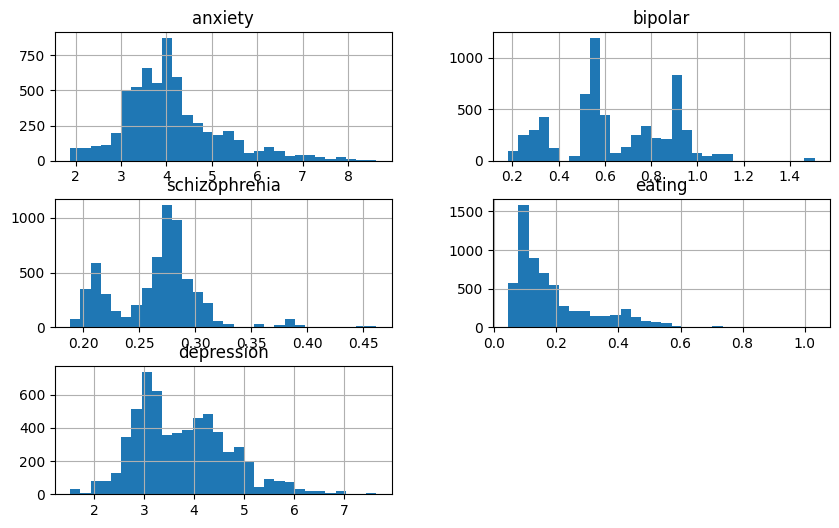

In [9]:
df[feats+["depression"]].hist(bins=30, figsize=(10,6))